# 02 – Real-Time Household Power Prediction

**Task (regression):** given the readings of the three appliance sub-meters, the line voltage and the date/hour,
predict the household's **total active power (kW)** at that moment.

**Algorithms:** Linear Regression, Decision Tree, Random Forest.

**Important note for the report / viva:** the sub-meters measure *parts* of the household's consumption
(kitchen, laundry, water heater + air-conditioner). So the task is *"estimate the total load from appliance readings"*.
We deliberately do **not** use `Global_intensity` or `Global_reactive_power`: power is voltage × current, so those would just
hand the answer to the model (data leakage).

Steps: 1) load and clean · 2) explore · 3) features · 4) split · 5) models · 6) compare · 7) plots · 8) cross-validation · 9) save for the app

## Step 1 – Load and clean the data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib, os, warnings
warnings.filterwarnings("ignore")

DATA_PATH = "../data/raw/household_power_consumption.txt"   # change if your path is different

df = pd.read_csv(DATA_PATH, sep=";", na_values="?", low_memory=False)
df["Datetime"] = pd.to_datetime(df["Date"] + " " + df["Time"], dayfirst=True)
df = df.drop(columns=["Date", "Time"]).set_index("Datetime").sort_index()

print("Rows before cleaning:", len(df))
print("Rows with missing values:", int(df.isna().any(axis=1).sum()))

# Not a time-series task any more, so rows with missing values can simply be dropped
cols = ["Sub_metering_1", "Sub_metering_2", "Sub_metering_3", "Voltage", "Global_active_power"]
clean = df[cols].dropna()
print("Rows after cleaning:", len(clean))
clean.describe().round(2)

Rows before cleaning: 2075259
Rows with missing values: 25979
Rows after cleaning: 2049280


,Sub_metering_1,Sub_metering_2,Sub_metering_3,Voltage,Global_active_power
count,2049280.00,2049280.00,2049280.00,2049280.00,2049280.00
mean,1.12,1.30,6.46,240.84,1.09
std,6.15,5.82,8.44,3.24,1.06
min,0.00,0.00,0.00,223.20,0.08
25%,0.00,0.00,0.00,238.99,0.31
50%,0.00,0.00,1.00,241.01,0.60
75%,0.00,1.00,17.00,242.89,1.53
max,88.00,80.00,31.00,254.15,11.12


Units: `Sub_metering_x` = energy used in that minute (Wh) by
1 = kitchen (dishwasher, oven, microwave), 2 = laundry room (washer, dryer, fridge, light),
3 = electric water heater + air-conditioner. `Voltage` is in volts. The target `Global_active_power` is in kW.

## Step 2 – Quick exploration

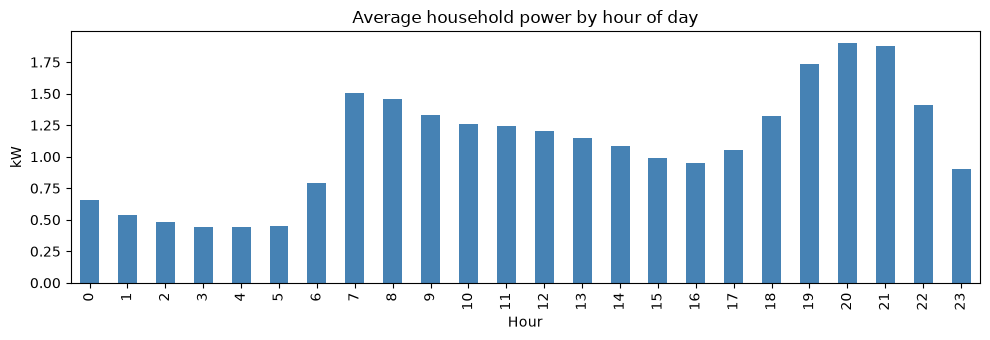

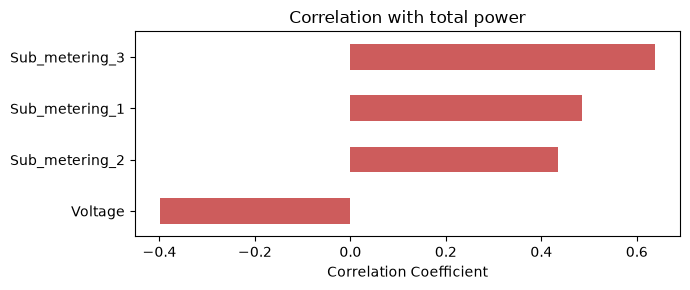

In [3]:
# 2. Hourly Profile Plot
hourly_profile = clean["Global_active_power"].groupby(clean.index.hour).mean()
hourly_profile.plot(kind="bar", figsize=(10, 3.5), color="steelblue")

plt.title("Average household power by hour of day")
plt.xlabel("Hour")
plt.ylabel("kW")
plt.tight_layout()
plt.show()

# 3. Correlation Plot
corr = clean.corr()["Global_active_power"].drop("Global_active_power").sort_values()
corr.plot(kind="barh", figsize=(7, 3), color="indianred")

plt.title("Correlation with total power")
plt.xlabel("Correlation Coefficient")
plt.tight_layout()
plt.show()

## Step 3 – Features

The user of the app will enter: three sub-meter readings, voltage, a date and an hour.
Everything else is derived from the date and hour. The **same function** is used in the app, so training and prediction match exactly.

In [4]:
def make_features(raw):
    """raw: DataFrame with Sub_metering_1/2/3, Voltage and a DatetimeIndex."""
    idx = raw.index
    out = pd.DataFrame(index=idx)
    out["Sub_metering_1"] = raw["Sub_metering_1"].values
    out["Sub_metering_2"] = raw["Sub_metering_2"].values
    out["Sub_metering_3"] = raw["Sub_metering_3"].values
    out["Voltage"] = raw["Voltage"].values
    out["hour_sin"] = np.sin(2 * np.pi * idx.hour / 24)       # cyclical hour
    out["hour_cos"] = np.cos(2 * np.pi * idx.hour / 24)
    out["day_of_week"] = idx.dayofweek
    out["is_weekend"] = (idx.dayofweek >= 5).astype(int)
    out["month"] = idx.month
    return out

X_all = make_features(clean)
y_all = clean["Global_active_power"]
features = list(X_all.columns)

print("Features:", features)
display(X_all.head())  # Use display() or print(X_all.head()) if running in a standard script

Features: ['Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3', 'Voltage', 'hour_sin', 'hour_cos', 'day_of_week', 'is_weekend', 'month']


,Sub_metering_1,Sub_metering_2,Sub_metering_3,Voltage,hour_sin,hour_cos,day_of_week,is_weekend,month
Datetime,,,,,,,,,
2006-12-16 17:24:00,0.0,1.0,17.0,234.84,-0.965926,-0.258819,5,1,12
2006-12-16 17:25:00,0.0,1.0,16.0,233.63,-0.965926,-0.258819,5,1,12
2006-12-16 17:26:00,0.0,2.0,17.0,233.29,-0.965926,-0.258819,5,1,12
2006-12-16 17:27:00,0.0,1.0,17.0,233.74,-0.965926,-0.258819,5,1,12
2006-12-16 17:28:00,0.0,1.0,17.0,235.68,-0.965926,-0.258819,5,1,12


## Step 4 – Train / test split (by time)

In [5]:
import numpy as np

split = int(len(clean) * 0.8)                     # earlier 80% = train, latest 20% = test
X_train, X_test = X_all.iloc[:split], X_all.iloc[split:]
y_train, y_test = y_all.iloc[:split], y_all.iloc[split:]

print("Train:", X_train.index.min().date(), "->", X_train.index.max().date(), "|", len(X_train), "rows")
print("Test :", X_test.index.min().date(),  "->", X_test.index.max().date(),  "|", len(X_test), "rows")

# For speed (and a small saved model) the models learn from a random sample of 300,000 training rows
rng = np.random.RandomState(42)
sample_idx = rng.choice(len(X_train), size=300_000, replace=False)
X_fit, y_fit = X_train.iloc[sample_idx], y_train.iloc[sample_idx]

Train: 2006-12-16 -> 2010-02-05 | 1639424 rows
Test : 2010-02-05 -> 2010-11-26 | 409856 rows


## Step 5 – Baseline and the three models

In [6]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

results, preds = {}, {}

def evaluate(name, y_true, y_pred):
    results[name] = {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }
    preds[name] = np.asarray(y_pred)

# Baseline: always predict the average power of the training data
evaluate("Baseline (always the mean)", y_test, np.full(len(y_test), y_train.mean()))

models = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Decision Tree":     DecisionTreeRegressor(max_depth=10, min_samples_leaf=50, random_state=42),
    "Random Forest":     RandomForestRegressor(n_estimators=60, max_depth=14, min_samples_leaf=20,
                                               random_state=42, n_jobs=-1),
}

fitted = {}
for name, model in models.items():
    model.fit(X_fit, y_fit)
    fitted[name] = model
    evaluate(name, y_test, model.predict(X_test))
    print(f"{name:20s} trained")

Linear Regression    trained
Decision Tree        trained
Random Forest        trained


## Step 6 – Compare the models

In [7]:
comparison = pd.DataFrame(results).T.sort_values("RMSE")
comparison.round(4)

,MAE,RMSE,R2
Random Forest,0.2152,0.3497,0.8477
Decision Tree,0.2314,0.3694,0.8300
Linear Regression,0.2972,0.3962,0.8045
Baseline (always the mean),0.7264,0.9009,-0.0110


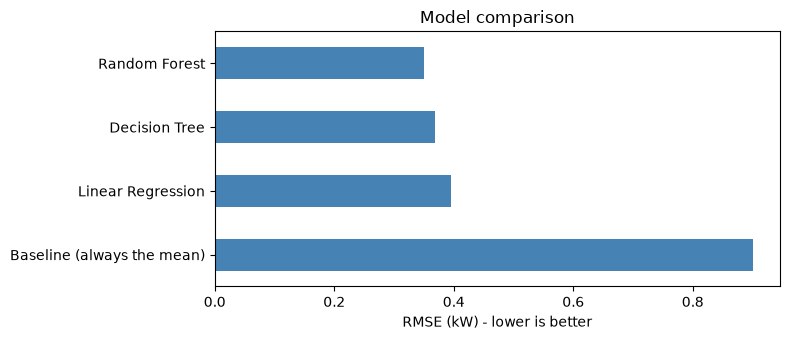

In [8]:
ax = comparison["RMSE"].plot(kind="barh", figsize=(8, 3.5), color="steelblue")
ax.set_xlabel("RMSE (kW) - lower is better"); ax.set_title("Model comparison"); ax.invert_yaxis()
plt.tight_layout(); plt.show()

## Step 7 – Plots and error analysis

Best model: Random Forest


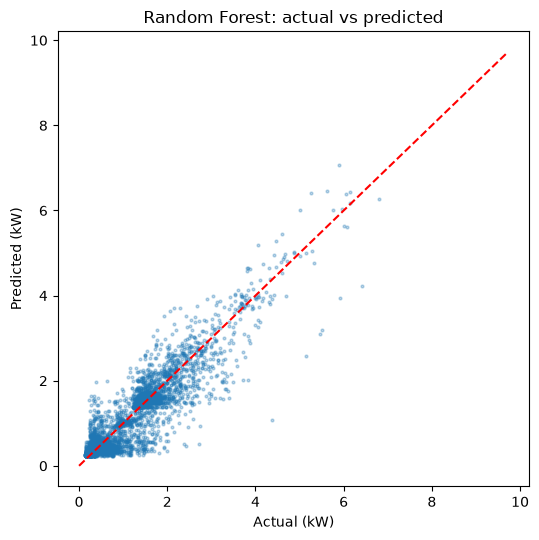

In [9]:
ml_names = list(models.keys())
best_name = comparison[comparison.index.isin(ml_names)].index[0]    # lowest RMSE among the three
print("Best model:", best_name)

# Actual vs predicted (random 5,000 test points)
pick = np.random.RandomState(0).choice(len(y_test), 5000, replace=False)
plt.figure(figsize=(5.5, 5.5))
plt.scatter(y_test.values[pick], preds[best_name][pick], s=4, alpha=0.3)

lim = [0, max(y_test.max(), preds[best_name].max())]
plt.plot(lim, lim, "r--")

plt.xlabel("Actual (kW)")
plt.ylabel("Predicted (kW)")
plt.title(f"{best_name}: actual vs predicted")
plt.tight_layout()
plt.show()

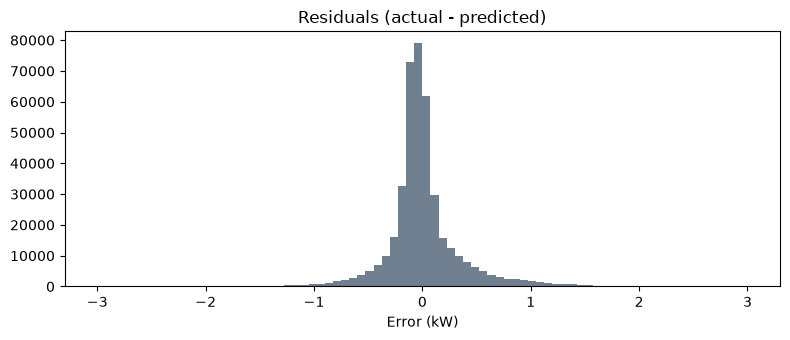

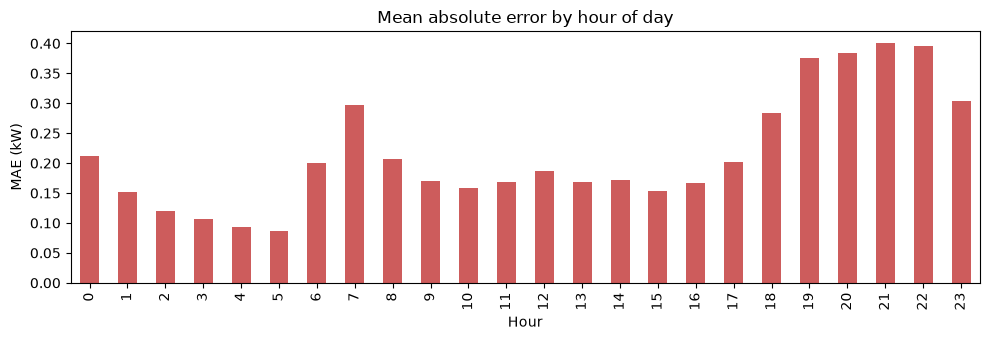

In [10]:
# 1. Residuals Histogram
residuals = y_test.values - preds[best_name]
plt.figure(figsize=(8, 3.5))
plt.hist(residuals, bins=80, color="slategray", range=(-3, 3))
plt.title("Residuals (actual - predicted)")
plt.xlabel("Error (kW)")
plt.tight_layout()
plt.show()

# 2. Error by Hour of Day
err = pd.DataFrame({"abs_err": np.abs(residuals), "hour": X_test.index.hour})
err.groupby("hour")["abs_err"].mean().plot(kind="bar", figsize=(10, 3.5), color="indianred")
plt.title("Mean absolute error by hour of day")
plt.ylabel("MAE (kW)")
plt.xlabel("Hour")
plt.tight_layout()
plt.show()

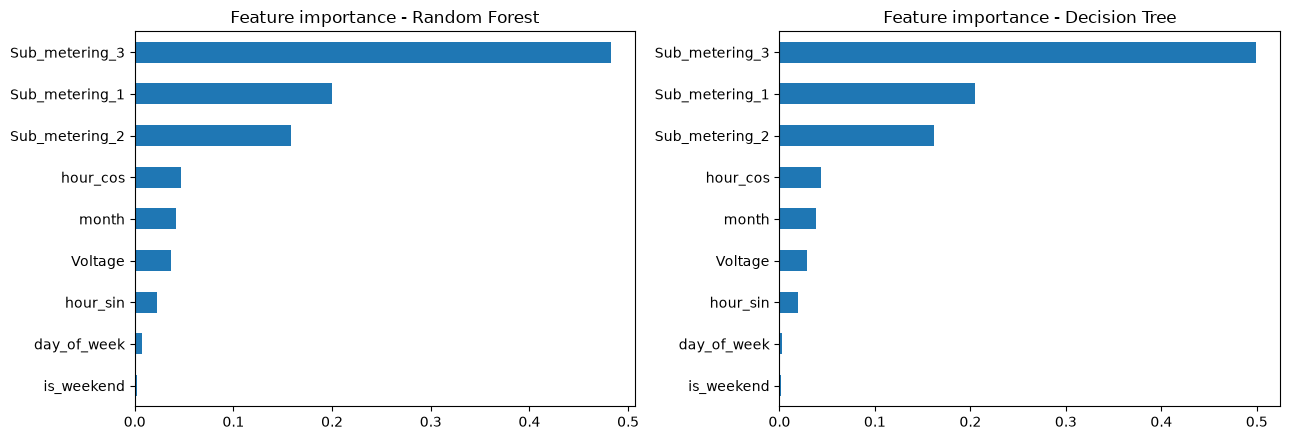

In [11]:
# Which inputs matter most?
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, name in zip(axes, ["Random Forest", "Decision Tree"]):
    pd.Series(fitted[name].feature_importances_, index=features).sort_values().plot(kind="barh", ax=ax)
    ax.set_title(f"Feature importance - {name}")
plt.tight_layout(); plt.show()

## Step 8 – Cross-validation (stability check)

In [12]:
from sklearn.model_selection import KFold
from sklearn.base import clone

# Sample 100,000 random rows to keep cross-validation fast
small = X_all.sample(100_000, random_state=1)
ys = y_all.loc[small.index]

kf = KFold(n_splits=5, shuffle=True, random_state=42)
rows = []

for name, model in models.items():
    for tr, te in kf.split(small):
        # Clone the model architecture to train fresh on each fold
        m = clone(model).fit(small.iloc[tr], ys.iloc[tr])
        p = m.predict(small.iloc[te])
        rows.append({
            "model": name, 
            "RMSE": np.sqrt(mean_squared_error(ys.iloc[te], p)), 
            "R2": r2_score(ys.iloc[te], p)
        })

# Aggregate cross-validation results (mean and standard deviation)
cv_summary = pd.DataFrame(rows).groupby("model")[["RMSE", "R2"]].agg(["mean", "std"]).round(4)
display(cv_summary)  # or just cv_summary if running directly in the notebook cell

RMSE              R2        
                     mean     std    mean     std
model                                            
Decision Tree      0.4580  0.0040  0.8109  0.0019
Linear Regression  0.5232  0.0042  0.7532  0.0036
Random Forest      0.4246  0.0042  0.8375  0.0018

## Step 9 – Save everything the Streamlit app needs

In [13]:
import os
import joblib
import pandas as pd

# Create output directories if they don't already exist
os.makedirs("../models", exist_ok=True)
os.makedirs("../data/processed", exist_ok=True)

# Build metadata dictionary from cleaned training dataset
meta = {
    "sub1_max": float(clean["Sub_metering_1"].max()),
    "sub2_max": float(clean["Sub_metering_2"].max()),
    "sub3_max": float(clean["Sub_metering_3"].max()),
    "volt_min": float(clean["Voltage"].min()),
    "volt_max": float(clean["Voltage"].max()),
    "power_mean": float(clean["Global_active_power"].mean()),
    "power_max": float(clean["Global_active_power"].max()),
}

# Save trained models, features list, best model name, and metadata
joblib.dump(
    {"models": fitted, "features": features, "best": best_name, "meta": meta},
    "../models/models.pkl",
    compress=3
)

# Ensure 'comparison' dataframe exists before saving
# comparison = pd.DataFrame(results).T.sort_values("RMSE")
comparison.round(4).to_csv("../models/model_comparison.csv")

# Extract a continuous week of real, unbroken minute readings from the test period for the app demo
test_df = clean.iloc[split:]
run_id = (test_df.index.to_series().diff() != pd.Timedelta(minutes=1)).cumsum()
longest = run_id.value_counts().idxmax()
live = test_df[run_id == longest].iloc[: 7 * 1440]  # 7 days * 1440 minutes/day
live.round(3).to_csv("../data/processed/live_sample.csv")

print("Saved models.pkl, model_comparison.csv, live_sample.csv. Best model:", best_name)
print("Live sample:", live.index.min(), "->", live.index.max(), f"({len(live)} rows)")

Saved models.pkl, model_comparison.csv, live_sample.csv. Best model: Random Forest
Live sample: 2010-02-14 21:24:00 -> 2010-02-21 21:23:00 (10080 rows)


## Summary (fill in after running)
- Best model: ...
- Best model RMSE / MAE / R²: ...
- Improvement over the mean baseline: ...
- Linear Regression vs Decision Tree vs Random Forest: ...
- Most important inputs: ...
- Limitations: one household (France, 2006–2010); sub-meters cover only part of the load; the models learn from past data and may not generalise to other homes.